# ⚡ PowerCast — Electricity Consumption Forecasting

**Team Member:** Renad Alotaibi  
**Role:** Feature Engineering & Model Training  
**Program:** SDA × Le Wagon Data Science Bootcamp

## Objective
Forecast household electricity consumption for the next 24 hours using the previous 168 hours of hourly data.

## Responsibilities
- Feature Engineering
- Baseline Models (Last-value, Seasonal Naive & Weekly Naive)
- Windowing & Scaling
- LSTM Model Training
- Model Evaluation (MAE & RMSE)
- Error Analysis
- Model Saving & Prediction Function

> **Update (13 Oct): final model = LSTM V4.** After TA feedback we added calendar features, training on a window at every hour, and the calendar of the next 24 hours as a second input. These experiments (LSTM V2–V7) are in `00_final_demo.ipynb`, sections 5d–5k. LSTM V4: validation MAE **0.464 kW** (Weekly Naive 0.580), test MAE **0.409 kW** (best baseline 0.479).

## 1. Imports & Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import joblib

from google.colab import drive
drive.mount('/content/drive')

# Project folders in Google Drive
BASE = '/content/drive/MyDrive/PowerCast'
MODELS = f'{BASE}/models'
FIGS = f'{BASE}/figures'
os.makedirs(MODELS, exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

SEED = 42
np.random.seed(SEED)


Mounted at /content/drive


## 2. Data Loading

Load the cleaned hourly electricity consumption dataset prepared by Rana.

In [ ]:

!pip -q install gdown

import gdown
import pandas as pd

file_id = "1p8-ngkHED_oQIxU8PaiHw4AhRQr_o2jr"

gdown.download(
    id=file_id,
    output="/content/hourly_clean.csv",
    quiet=False
)

df = pd.read_csv(
    "/content/hourly_clean.csv",
    parse_dates=["datetime"]
)

print("Data shape:", df.shape)
display(df.head())


Downloading...
From: https://drive.google.com/uc?id=1p8-ngkHED_oQIxU8PaiHw4AhRQr_o2jr
To: /content/hourly_clean.csv
100%|██████████| 4.19M/4.19M [00:00<00:00, 35.0MB/s]


Data shape: (34589, 10)


,datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,was_missing,split
0,2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,0,train
1,2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,0,train
2,2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,0,train
3,2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,0,train
4,2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,0,train


## 3. Time Series Preparation

Prepare the hourly electricity consumption data in chronological order. Set the datetime column as the index and verify the predefined Train, Validation and Test splits and missing target values.

In [ ]:


df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime").set_index("datetime")

print("Date range:", df.index.min(), "to", df.index.max())
print("\nData splits:")
print(df["split"].value_counts())

print("\nMissing target values:")
print(df["Global_active_power"].isna().sum())


Date range: 2006-12-16 17:00:00 to 2010-11-26 21:00:00

Data splits:
split
train    26671
val       4344
test      3574
Name: count, dtype: int64

Missing target values:
0


## 4. Feature Engineering — Time Features

Extract calendar-based features from the datetime index to capture hourly, weekly and monthly electricity consumption patterns.

The generated features include hour, day of week, month and weekend indicator.

In [ ]:


df["hour"] = df.index.hour
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)

display(df[[
    "Global_active_power",
    "hour",
    "day_of_week",
    "month",
    "is_weekend"
]].head())


,Global_active_power,hour,day_of_week,month,is_weekend
datetime,,,,,
2006-12-16 17:00:00,4.222889,17,5,12,1
2006-12-16 18:00:00,3.632200,18,5,12,1
2006-12-16 19:00:00,3.400233,19,5,12,1
2006-12-16 20:00:00,3.268567,20,5,12,1
2006-12-16 21:00:00,3.056467,21,5,12,1


## 5. Feature Engineering — Lag Features

Create lag features to examine historical electricity consumption patterns at different time intervals.

The selected lags represent consumption 1 hour, 24 hours and 168 hours earlier.

In [ ]:


for lag in [1, 24, 168]:
    df[f"lag_{lag}"] = df["Global_active_power"].shift(lag)

display(df[[
    "Global_active_power",
    "lag_1",
    "lag_24",
    "lag_168"
]].iloc[168:173])


,Global_active_power,lag_1,lag_24,lag_168
datetime,,,,
2006-12-23 17:00:00,5.452533,4.349100,1.496800,4.222889
2006-12-23 18:00:00,3.879400,5.452533,2.686967,3.632200
2006-12-23 19:00:00,4.117833,3.879400,3.938167,3.400233
2006-12-23 20:00:00,4.181400,4.117833,3.536067,3.268567
2006-12-23 21:00:00,3.288433,4.181400,4.548667,3.056467


## 6. Baseline Models

Three baseline methods are used:
- **Last-value:** Repeats the most recent observed consumption value.
- **Seasonal Naive:** Repeats the consumption pattern from the previous day.
- **Weekly Naive:** Repeats the consumption pattern from the same day last week.

In [ ]:
import numpy as np

target = "Global_active_power"

val = df[df["split"] == "val"].copy()

# Use the previous 168 hours to predict the next 24
history = 168
horizon = 24

# First validation forecast
first_val_time = val.index[0]
start_pos = df.index.get_loc(first_val_time)

past_168 = df[target].iloc[start_pos-history:start_pos].to_numpy()
actual_24 = df[target].iloc[start_pos:start_pos+horizon].to_numpy()

last_value_pred = np.repeat(past_168[-1], horizon)

print("History shape:", past_168.shape)
print("Actual shape:", actual_24.shape)
print("Prediction shape:", last_value_pred.shape)
print("Last known value:", past_168[-1])


History shape: (168,)
Actual shape: (24,)
Prediction shape: (24,)
Last known value: 1.6905


In [ ]:

# 6. Seasonal Naive Baseline

# Repeat the last 24 hours as the next 24-hour forecast
seasonal_pred = past_168[-24:].copy()

print("Seasonal prediction shape:", seasonal_pred.shape)

print("\nFirst 5 predictions:")
print(seasonal_pred[:5])


Seasonal prediction shape: (24,)

First 5 predictions:
[0.3377     0.37203333 0.3641     0.36393333 0.31946667]


## 7. Baseline Evaluation — First 24 Hours

Evaluate the Last-value and Seasonal Naive baselines against actual electricity consumption during the first 24 hours of the validation period.

Performance is measured using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Lower values indicate better forecasting accuracy.

In [ ]:

# 7. Evaluate Baselines - First 24 Hours

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

last_mae, last_rmse = evaluate(actual_24, last_value_pred)
seasonal_mae, seasonal_rmse = evaluate(actual_24, seasonal_pred)

print("Last-value Baseline:")
print(f"MAE: {last_mae:.4f} kW")
print(f"RMSE: {last_rmse:.4f} kW")

print("\nSeasonal Naive Baseline:")
print(f"MAE: {seasonal_mae:.4f} kW")
print(f"RMSE: {seasonal_rmse:.4f} kW")


Last-value Baseline:
MAE: 0.9550 kW
RMSE: 1.0020 kW

Seasonal Naive Baseline:
MAE: 1.0177 kW
RMSE: 1.2651 kW


### 8. Baseline Evaluation — Full Validation Set

Evaluate both baseline models across the entire validation period using non-overlapping 24-hour forecasting windows.

Performance is measured using MAE and RMSE over 4,344 validation hours.

Seasonal Naive beats Last-value. Weekly Naive (section 8b) gives the lowest error and is the main benchmark for the LSTM.

In [ ]:


val_start = df.index.get_loc(
    df[df["split"] == "val"].index[0]
)

val_length = (df["split"] == "val").sum()

actual_all = []
last_all = []
seasonal_all = []

for offset in range(0, val_length - horizon + 1, horizon):
    pos = val_start + offset

    past = df[target].iloc[pos-history:pos].to_numpy()
    actual = df[target].iloc[pos:pos+horizon].to_numpy()

    actual_all.extend(actual)
    last_all.extend(np.repeat(past[-1], horizon))
    seasonal_all.extend(past[-24:])

results = pd.DataFrame({
    "Model": ["Last-value", "Seasonal Naive"],
    "MAE": [
        mean_absolute_error(actual_all, last_all),
        mean_absolute_error(actual_all, seasonal_all)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual_all, last_all)),
        np.sqrt(mean_squared_error(actual_all, seasonal_all))
    ]
})

display(results.round(4))
print("Evaluated hours:", len(actual_all))


,Model,MAE,RMSE
0,Last-value,0.7491,1.0077
1,Seasonal Naive,0.6153,0.8822


Evaluated hours: 4344


### 8b. Weekly Naive Baseline (lag 168)

Repeat the same 24 hours from exactly one week earlier (same hours, same weekdays).
This is the "same hour, last week" baseline from the project plan.
It uses only past data: hours t-168 to t-145 forecast hours t to t+23.

In [ ]:
# Weekly Naive: same hour, last week (lag 168), on the same non-overlapping validation windows
weekly_all = []

for offset in range(0, val_length - horizon + 1, horizon):
    pos = val_start + offset
    past = df[target].iloc[pos-history:pos].to_numpy()   # 168 past hours
    weekly_all.extend(past[:horizon])                    # hours t-168 ... t-145

weekly_mae = mean_absolute_error(actual_all, weekly_all)
weekly_rmse = np.sqrt(mean_squared_error(actual_all, weekly_all))

print(f"Weekly Naive Validation MAE:  {weekly_mae:.4f} kW")
print(f"Weekly Naive Validation RMSE: {weekly_rmse:.4f} kW")
print("Evaluated hours:", len(weekly_all))

Weekly Naive Validation MAE:  0.5796 kW
Weekly Naive Validation RMSE: 0.8392 kW
Evaluated hours: 4344


### 8c. Save Baseline Predictions

Save the hourly validation forecasts of all baselines next to the actual values, not only the scores.

In [ ]:
val_times = df.index[val_start : val_start + len(actual_all)]

baseline_preds = pd.DataFrame({
    "datetime": val_times,
    "actual": actual_all,
    "last_value": last_all,
    "seasonal_naive": seasonal_all,
    "weekly_naive": weekly_all,
})

os.makedirs(f"{BASE}/data", exist_ok=True)
baseline_preds.to_csv(f"{BASE}/data/baseline_predictions_val.csv", index=False)

print("Saved rows:", len(baseline_preds))
display(baseline_preds.head())

Saved rows: 4344


,datetime,actual,last_value,seasonal_naive,weekly_naive
0,2010-01-01 00:00:00,1.085867,1.6905,0.337700,1.660700
1,2010-01-01 01:00:00,0.651233,1.6905,0.372033,1.405700
2,2010-01-01 02:00:00,0.634600,1.6905,0.364100,1.099300
3,2010-01-01 03:00:00,0.653000,1.6905,0.363933,0.309133
4,2010-01-01 04:00:00,0.646067,1.6905,0.319467,0.300333


### 9. Target Scaling — Training Data Only

Standardize electricity consumption values using `StandardScaler` to prepare the data for LSTM training.

The scaler is fitted only on the training set to prevent data leakage. The same scaler is then applied to all data splits.

This scaler will also be used to convert predictions back to their original unit (kW).


In [ ]:


from sklearn.preprocessing import StandardScaler

train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

scaler = StandardScaler()

scaler.fit(train[[target]])

df["power_scaled"] = scaler.transform(df[[target]]).ravel()

print("Train mean:", round(scaler.mean_[0], 4))
print("Train scale:", round(scaler.scale_[0], 4))

print("\nScaled values:")
display(df[[target, "power_scaled"]].head())


Train mean: 1.1
Train scale: 0.9276

Scaled values:


,Global_active_power,power_scaled
datetime,,
2006-12-16 17:00:00,4.222889,3.366565
2006-12-16 18:00:00,3.632200,2.729777
2006-12-16 19:00:00,3.400233,2.479708
2006-12-16 20:00:00,3.268567,2.337765
2006-12-16 21:00:00,3.056467,2.109112


### 10. LSTM Window Creation — 168 to 24 Hours

Convert the scaled electricity consumption series into supervised learning samples.

Each input window contains 168 hours (7 days) of historical consumption. The corresponding target contains the next 24 hours.

The windows are assigned to training, validation and test sets based on their target timestamps.

In [ ]:
# 10. Create LSTM Windows (168 -> 24)

history = 168
horizon = 24

values = df["power_scaled"].to_numpy()
splits = df["split"].to_numpy()

X_train, y_train = [], []
X_val, y_val = [], []
X_test, y_test = [], []

# Create windows separately for each target split
for split_name in ["train", "val", "test"]:

    positions = np.where(splits == split_name)[0]
    split_start = positions[0]
    split_end = positions[-1] + 1

    for start in range(max(history, split_start),
                       split_end - horizon + 1,
                       horizon):

        X = values[start-history:start]
        y = values[start:start+horizon]

        if split_name == "train":
            X_train.append(X)
            y_train.append(y)

        elif split_name == "val":
            X_val.append(X)
            y_val.append(y)

        else:
            X_test.append(X)
            y_test.append(y)

X_train = np.array(X_train).reshape(-1, history, 1)
X_val = np.array(X_val).reshape(-1, history, 1)
X_test = np.array(X_test).reshape(-1, history, 1)

y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (1104, 168, 1)
y_train: (1104, 24)
X_val: (181, 168, 1)
y_val: (181, 24)
X_test: (148, 168, 1)
y_test: (148, 24)


In [ ]:
print("Validation hours:", (df["split"] == "val").sum())
print("LSTM validation hours:", len(y_val) * horizon)
print("Difference:", (df["split"] == "val").sum() - len(y_val) * horizon)

Validation hours: 4344
LSTM validation hours: 4344
Difference: 0


In [ ]:
# Check feature safety before modeling

target = "Global_active_power"

lstm_features = ["power_scaled"]

assert "Global_intensity" not in lstm_features

assert all(
    lag > 0 for lag in [1, 24, 168]
)

print("Feature checks passed.")

Feature checks passed.


In [ ]:
# Time Series Cross-Validation: fold boundaries only

from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=24 * 30,
    gap=24
)

print("3 temporal folds configured.")
print("Validation window: 30 days per fold.")
print("Gap: 24 hours.")

3 temporal folds configured.
Validation window: 30 days per fold.
Gap: 24 hours.


In [ ]:
# Inspect temporal CV folds (Train only)

train_cv = df.loc[
    df["split"] == "train",
    [target]
].copy()

fold_info = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(train_cv), start=1
):
    fold_info.append({
        "Fold": fold,
        "Train hours": len(train_idx),
        "Train end": train_cv.index[train_idx[-1]],
        "Validation start": train_cv.index[val_idx[0]],
        "Validation hours": len(val_idx)
    })

display(pd.DataFrame(fold_info))

,Fold,Train hours,Train end,Validation start,Validation hours
0,1,24487,2009-10-01 23:00:00,2009-10-03,720
1,2,25207,2009-10-31 23:00:00,2009-11-02,720
2,3,25927,2009-11-30 23:00:00,2009-12-02,720


In [ ]:
# Temporal Cross-Validation: LSTM (Train only)

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping


def calculate_smape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    denominator = np.abs(actual) + np.abs(predicted)

    values = np.divide(
        2 * np.abs(actual - predicted),
        denominator,
        out=np.zeros_like(actual, dtype=float),
        where=denominator > 0
    )

    return 100 * np.mean(values)


def calculate_metrics(actual, predicted):
    return {
        "MAE (kW)": mean_absolute_error(actual, predicted),
        "RMSE (kW)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "sMAPE (%)": calculate_smape(actual, predicted),
        "R2": r2_score(actual, predicted)
    }


cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(train_cv), start=1
):

    print(f"\nTraining Fold {fold}/3...")

    # 1. Training data and validation data in kW
    train_values = train_cv[target].iloc[train_idx].to_numpy()
    val_values = train_cv[target].iloc[val_idx].to_numpy()

    # 2. Use the 168 hours before validation as history
    # Gap hours are context only, not training targets
    val_start_pos = val_idx[0]
    context_start = val_start_pos - history

    if context_start < 0:
        raise ValueError("Not enough history for validation.")

    validation_context = train_cv[target].iloc[
        context_start:val_start_pos
    ].to_numpy()

    # 3. Fit scaler on fold training data only
    fold_scaler = StandardScaler()

    fold_scaler.fit(
        train_values.reshape(-1, 1)
    )

    train_scaled = fold_scaler.transform(
        train_values.reshape(-1, 1)
    ).ravel()

    context_scaled = fold_scaler.transform(
        validation_context.reshape(-1, 1)
    ).ravel()

    val_scaled = fold_scaler.transform(
        val_values.reshape(-1, 1)
    ).ravel()

    # 4. Create training windows: 168 -> 24
    X_fold, y_fold = [], []

    for start in range(
        history,
        len(train_scaled) - horizon + 1,
        horizon
    ):
        X_fold.append(
            train_scaled[start-history:start]
        )

        y_fold.append(
            train_scaled[start:start+horizon]
        )

    X_fold = np.asarray(X_fold).reshape(
        -1, history, 1
    )

    y_fold = np.asarray(y_fold)

    # 5. Create external validation windows
    combined = np.concatenate([
        context_scaled,
        val_scaled
    ])

    X_cv_val = []
    y_cv_val = []
    seasonal_predictions = []

    for start in range(
        history,
        len(combined) - horizon + 1,
        horizon
    ):
        past = combined[start-history:start]
        future = combined[start:start+horizon]

        X_cv_val.append(past)
        y_cv_val.append(future)

        # Seasonal Naive: same 24 hours yesterday
        seasonal_predictions.append(
            past[-horizon:]
        )

    X_cv_val = np.asarray(X_cv_val).reshape(
        -1, history, 1
    )

    y_cv_val = np.asarray(y_cv_val)

    seasonal_predictions = np.asarray(
        seasonal_predictions
    )

    # 6. Build a fresh LSTM for each fold
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42 + fold)

    fold_model = Sequential([
        Input(shape=(history, 1)),
        LSTM(32),
        Dense(horizon)
    ])

    fold_model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    # 7. Train with internal validation for EarlyStopping
    # External CV validation is not used during training
    fold_model.fit(
        X_fold,
        y_fold,
        validation_split=0.1,
        shuffle=False,
        epochs=30,
        batch_size=32,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # 8. Predict external validation period
    pred_scaled = fold_model.predict(
        X_cv_val,
        verbose=0
    )

    # 9. Convert predictions back to kW
    actual_kw = fold_scaler.inverse_transform(
        y_cv_val.reshape(-1, 1)
    ).ravel()

    lstm_kw = fold_scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    seasonal_kw = fold_scaler.inverse_transform(
        seasonal_predictions.reshape(-1, 1)
    ).ravel()

    # 10. Evaluate both models
    for model_name, predictions in [
        ("LSTM", lstm_kw),
        ("Seasonal Naive", seasonal_kw)
    ]:
        cv_results.append({
            "Fold": fold,
            "Model": model_name,
            **calculate_metrics(
                actual_kw,
                predictions
            )
        })

    print(f"Fold {fold} completed.")


# 11. Display results
cv_results_df = pd.DataFrame(cv_results)

print("\nCross-validation results:")
display(cv_results_df.round(4))

print("\nAverage metrics across folds:")
cv_summary = (
    cv_results_df
    .groupby("Model")[
        ["MAE (kW)", "RMSE (kW)", "sMAPE (%)", "R2"]
    ]
    .mean()
    .round(4)
)

display(cv_summary)


Training Fold 1/3...
Fold 1 completed.

Training Fold 2/3...
Fold 2 completed.

Training Fold 3/3...
Fold 3 completed.

Cross-validation results:


,Fold,Model,MAE (kW),RMSE (kW),sMAPE (%),R2
0,1,LSTM,0.9523,1.1330,81.7524,-0.6866
1,1,Seasonal Naive,0.6787,0.9825,55.3099,-0.2684
2,2,LSTM,1.0415,1.2456,81.2351,-0.7615
3,2,Seasonal Naive,0.6933,1.0098,51.5708,-0.1575
4,3,LSTM,1.0386,1.2556,78.0934,-0.7673
5,3,Seasonal Naive,0.7284,1.0178,54.1280,-0.1614



Average metrics across folds:


,MAE (kW),RMSE (kW),sMAPE (%),R2
Model,,,,
LSTM,1.0108,1.2114,80.3603,-0.7385
Seasonal Naive,0.7001,1.0034,53.6695,-0.1958


## 11. LSTM Model Building

Build a small LSTM neural network to predict the next 24 hours of electricity consumption using the previous 168 hours.

In [ ]:

# 11. Build LSTM Model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

tf.random.set_seed(42)

model = Sequential([
    Input(shape=(168, 1)),
    LSTM(32),
    Dense(24)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144 (20.09 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

## 12. LSTM Model Training

Train the LSTM model using the training windows and monitor validation performance to reduce overfitting.


In [ ]:

# 12. Train LSTM Model

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_lstm = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.9338 - mae: 0.7777 - val_loss: 0.8640 - val_mae: 0.7761
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.7231 - mae: 0.6536 - val_loss: 1.3503 - val_mae: 0.9695
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.6490 - mae: 0.5910 - val_loss: 1.4188 - val_mae: 0.9896
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.6343 - mae: 0.5792 - val_loss: 1.4387 - val_mae: 0.9955
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.6312 - mae: 0.5777 - val_loss: 1.4404 - val_mae: 0.9957
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.6281 - mae: 0.5753 - val_loss: 1.4447 - val_mae: 0.9970


In [ ]:
print("Completed epochs:", len(history_lstm.history["loss"]))
print("Best epoch:", np.argmin(history_lstm.history["val_loss"]) + 1)
print("Best val_loss:", min(history_lstm.history["val_loss"]))

Completed epochs: 6
Best epoch: 1
Best val_loss: 0.8639929890632629


In [ ]:
training_results = pd.DataFrame(history_lstm.history)
display(training_results.round(4))

,loss,mae,val_loss,val_mae
0,0.9338,0.7777,0.8640,0.7761
1,0.7231,0.6536,1.3503,0.9695
2,0.6490,0.5910,1.4188,0.9896
3,0.6343,0.5792,1.4387,0.9955
4,0.6312,0.5777,1.4404,0.9957
5,0.6281,0.5753,1.4447,0.9970


## 13. LSTM V1 — Validation Evaluation

Evaluate the first LSTM model on the validation set using MAE and RMSE.

Predictions and actual values are converted back to kW before calculating the errors.

The results will be used to compare LSTM V1 with the baseline models and LSTM V1b.

In [ ]:

# 13. Evaluate LSTM on Validation

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict validation windows
y_val_pred_scaled = model.predict(X_val, verbose=0)

# Convert predictions and actual values back to kW
y_val_pred = scaler.inverse_transform(
    y_val_pred_scaled.reshape(-1, 1)
).reshape(y_val_pred_scaled.shape)

y_val_actual = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(y_val.shape)

# Calculate errors
lstm_mae = mean_absolute_error(
    y_val_actual.flatten(),
    y_val_pred.flatten()
)

lstm_rmse = np.sqrt(mean_squared_error(
    y_val_actual.flatten(),
    y_val_pred.flatten()
))

print(f"LSTM Validation MAE: {lstm_mae:.4f} kW")
print(f"LSTM Validation RMSE: {lstm_rmse:.4f} kW")
print("Predictions shape:", y_val_pred.shape)


LSTM Validation MAE: 0.7199 kW
LSTM Validation RMSE: 0.8622 kW
Predictions shape: (181, 24)


In [ ]:
print("Actual first 5 hours:", np.round(y_val_actual[0, :5], 3))
print("LSTM first 5 hours:", np.round(y_val_pred[0, :5], 3))
print("Actual mean:", round(y_val_actual.mean(), 3))
print("Predicted mean:", round(y_val_pred.mean(), 3))

Actual first 5 hours: [1.086 0.651 0.635 0.653 0.646]
LSTM first 5 hours: [1.619 1.522 2.036 1.514 1.767]
Actual mean: 1.17
Predicted mean: 1.248


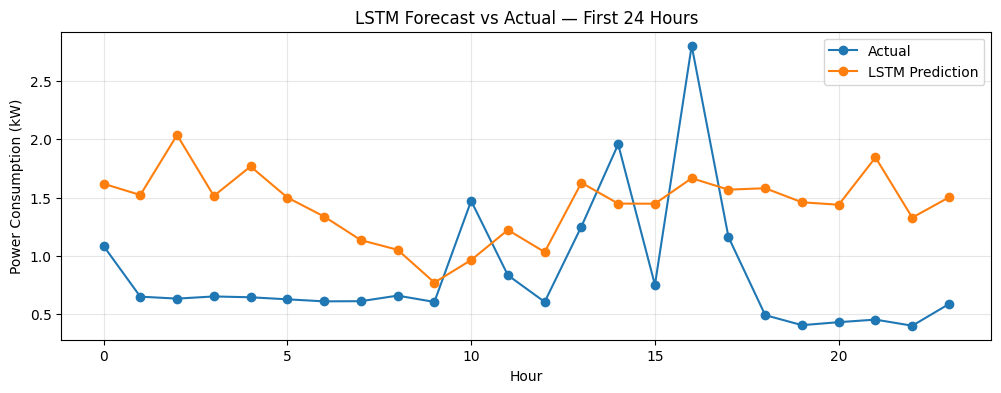

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.plot(y_val_actual[0], label="Actual", marker="o")
plt.plot(y_val_pred[0], label="LSTM Prediction", marker="o")

plt.title("LSTM Forecast vs Actual — First 24 Hours")
plt.xlabel("Hour")
plt.ylabel("Power Consumption (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
print("Baseline hours:", len(actual_all))
print("LSTM hours:", y_val_actual.size)

print("Same actual values:",
      np.allclose(actual_all, y_val_actual.flatten()))

Baseline hours: 4344
LSTM hours: 4344
Same actual values: True


## 14. LSTM V1b — Bigger Model

> Named **"LSTM V2"** in the code and tables of this notebook. It is a different experiment from **LSTM V2** in `00_final_demo.ipynb` (calendar features).

We developed a second (bigger) LSTM model to improve forecasting performance.

Compared with LSTM V1, this model uses 64 LSTM units and an additional Dense layer with 32 neurons and ReLU activation.

The model takes the previous 168 hours of electricity consumption and predicts the next 24 hours.

We will evaluate LSTM V1b ("LSTM V2" in the code) on the validation set to check whether these changes improve forecasting accuracy.

In [ ]:
from tensorflow.keras.optimizers import Adam

model_v2 = Sequential([
    Input(shape=(168, 1)),
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(24)
])

model_v2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model_v2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,768 (77.22 KB)

 Trainable params: 19,768 (77.22 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop_v2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_v2 = model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop_v2],
    verbose=1
)

print("Completed epochs:", len(history_v2.history["loss"]))
print("Best epoch:", np.argmin(history_v2.history["val_loss"]) + 1)
print("Best val_loss:", min(history_v2.history["val_loss"]))

Epoch 1/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.8611 - mae: 0.7363 - val_loss: 1.3573 - val_mae: 0.9763
Epoch 2/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.6788 - mae: 0.6093 - val_loss: 1.5498 - val_mae: 1.0392
Epoch 3/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.6430 - mae: 0.5850 - val_loss: 1.4410 - val_mae: 0.9936
Epoch 4/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.6335 - mae: 0.5773 - val_loss: 1.4541 - val_mae: 0.9981
Epoch 5/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.6291 - mae: 0.5742 - val_loss: 1.4394 - val_mae: 0.9927
Epoch 6/30
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.6245 - mae: 0.5716 - val_loss: 1.4510 - val_mae: 0.9972
Completed epochs: 6
Best epoch: 1
Best val_loss: 1.3572678565979004


In [ ]:
# Evaluate LSTM V2 on Validation

y_val_pred_v2_scaled = model_v2.predict(X_val, verbose=0)

y_val_pred_v2 = scaler.inverse_transform(
    y_val_pred_v2_scaled.reshape(-1, 1)
).reshape(y_val_pred_v2_scaled.shape)

v2_mae = mean_absolute_error(
    y_val_actual.flatten(),
    y_val_pred_v2.flatten()
)

v2_rmse = np.sqrt(mean_squared_error(
    y_val_actual.flatten(),
    y_val_pred_v2.flatten()
))

print(f"LSTM V2 MAE: {v2_mae:.4f} kW")
print(f"LSTM V2 RMSE: {v2_rmse:.4f} kW")

LSTM V2 MAE: 0.9057 kW
LSTM V2 RMSE: 1.0807 kW


In [ ]:
# Verify V2 evaluation consistency

val_mse_v2, val_mae_v2_scaled = model_v2.evaluate(
    X_val, y_val, verbose=0
)

print("Keras validation MSE:", round(val_mse_v2, 4))
print("Manual validation MSE:",
      round(np.mean((y_val - y_val_pred_v2_scaled) ** 2), 4))
print("Keras validation MAE:", round(val_mae_v2_scaled, 4))
print("Scaler standard deviation:", round(scaler.scale_[0], 4))

Keras validation MSE: 1.3573
Manual validation MSE: 1.3573
Keras validation MAE: 0.9763
Scaler standard deviation: 0.9276


### 15. Model Comparison on Validation

We compared five models on the same validation period (4,344 hours) using MAE (primary metric), RMSE, sMAPE and R².

**Weekly Naive** (same hour, last week) achieved the best result on all four metrics.
**Seasonal Naive** was second on MAE and sMAPE.
**LSTM V1** was the best LSTM: it beat LSTM V1b ("LSTM V2" in the tables) and Last-value, but it did not beat the naive baselines on MAE.

At this stage (12 Oct), **Weekly Naive** was the best method. The LSTM models were kept as experiments.

> **Update (13 Oct): final model = LSTM V4.** After TA feedback we added calendar features, training on a window at every hour, and the calendar of the next 24 hours as a second input. These experiments (LSTM V2–V7) are in `00_final_demo.ipynb`, sections 5d–5k. LSTM V4: validation MAE **0.464 kW** (Weekly Naive 0.580), test MAE **0.409 kW** (best baseline 0.479).

The final test-set evaluation will be performed once in the combined project notebook.

In [ ]:
from sklearn.metrics import r2_score
import numpy as np

def smape(y_true, y_pred):
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()

    denominator = np.abs(y_true) + np.abs(y_pred)

    return 100 * np.mean(
        np.divide(
            2 * np.abs(y_true - y_pred),
            denominator,
            out=np.zeros_like(denominator, dtype=float),
            where=denominator != 0
        )
    )

model_predictions = {
    "Last-value": np.asarray(last_all),
    "Seasonal Naive": np.asarray(seasonal_all),
    "Weekly Naive": np.asarray(weekly_all),
    "LSTM V1": y_val_pred.flatten(),
    "LSTM V2": y_val_pred_v2.flatten()
}

actual_values = np.asarray(actual_all)

for name, pred in model_predictions.items():
    print(
        name,
        "| sMAPE:", round(smape(actual_values, pred), 2),
        "| R²:", round(r2_score(actual_values, pred), 4)
    )

Last-value | sMAPE: 67.26 | R²: -0.5381
Seasonal Naive | sMAPE: 51.62 | R²: -0.1788
Weekly Naive | sMAPE: 49.14 | R²: -0.0666
LSTM V1 | sMAPE: 64.25 | R²: -0.126
LSTM V2 | sMAPE: 76.5 | R²: -0.7689


In [ ]:
comparison = pd.DataFrame({
    "Model": list(model_predictions.keys()),
    "MAE (kW)": [mean_absolute_error(actual_values, p) for p in model_predictions.values()],
    "RMSE (kW)": [np.sqrt(mean_squared_error(actual_values, p)) for p in model_predictions.values()],
    "sMAPE (%)": [smape(actual_values, p) for p in model_predictions.values()],
    "R²": [r2_score(actual_values, p) for p in model_predictions.values()],
})

comparison = comparison.sort_values("MAE (kW)").reset_index(drop=True)

display(comparison.round(4))

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
1,Seasonal Naive,0.6153,0.8822,51.6243,-0.1788
2,LSTM V1,0.7199,0.8622,64.2533,-0.1260
3,Last-value,0.7491,1.0077,67.2551,-0.5381
4,LSTM V2,0.9057,1.0807,76.4967,-0.7689


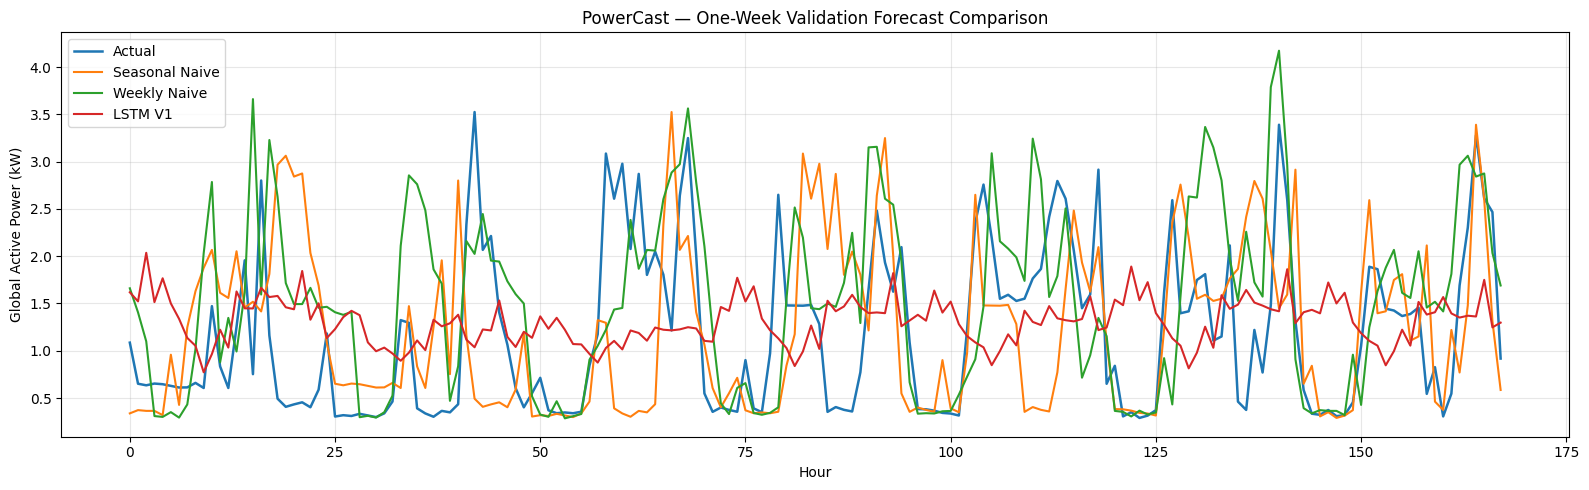

Weekly comparison figure saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# First week of Validation: 168 hours
week_hours = 168

actual_week = np.asarray(actual_all)[:week_hours]
seasonal_week = np.asarray(seasonal_all)[:week_hours]
weekly_week = np.asarray(weekly_all)[:week_hours]
lstm_week = y_val_pred.flatten()[:week_hours]

# Create comparison plot
plt.figure(figsize=(16, 5))

plt.plot(actual_week, label="Actual", linewidth=1.8)
plt.plot(seasonal_week, label="Seasonal Naive", linewidth=1.5)
plt.plot(weekly_week, label="Weekly Naive", linewidth=1.5)
plt.plot(lstm_week, label="LSTM V1", linewidth=1.5)

plt.title("PowerCast — One-Week Validation Forecast Comparison")
plt.xlabel("Hour")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure as PNG
plt.savefig(
    f"{FIGS}/powercast_weekly_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekly comparison figure saved successfully!")

### 15b. Experiment Log

Every experiment is recorded with what changed, why, and what happened. All numbers are validation MAE in kW (4,344 hours) unless noted.

| # | Experiment | What changed | Why | Result |
|---|---|---|---|---|
| 1 | Last-value | Repeat the last observed hour for 24 hours | Simplest possible baseline | MAE 0.7491 |
| 2 | Seasonal Naive | Repeat yesterday (lag 24) | Daily pattern is strong | MAE 0.6153, better than #1 |
| 3 | Weekly Naive | Repeat the same hours last week (lag 168) | Autocorrelation peaks at 168h (EDA) | **MAE 0.5796, best overall** |
| 4 | LSTM V1 | LSTM(32) + Dense(24), windows of 168 to 24 | First deep-learning model | MAE 0.7199; best epoch was 1 and validation loss then got worse |
| 5 | LSTM V1b ("LSTM V2" in the tables) | LSTM(64) + extra Dense(32, ReLU) + explicit Adam lr 0.001 | Try a bigger model | MAE 0.9057, worse than V1 |
| 6 | Time-series CV (train only, 3 folds) | LSTM vs Seasonal Naive on 30-day folds | Check the result is not due to one split | Average MAE: LSTM 1.0108 vs Seasonal Naive 0.7001; naive wins in every fold |
| 7 | LSTM V2 (`00_final_demo` 5d) | + is_weekend, hour sin/cos of the past 168 hours; 1,104 daily windows | TA feedback: calendar features | MAE 0.7435, no gain |
| 8 | LSTM V3 (`00_final_demo` 5e) | Same features, a window starting at every hour (~26,000 samples) | Next experiment from the notes below | MAE 0.4740, first LSTM to beat Weekly Naive |
| 9 | **LSTM V4 (final)** (`00_final_demo` 5f) | + calendar of the next 24 hours (is_weekend, hour sin/cos) as a second input | TA feedback: tomorrow's calendar is known in advance | **MAE 0.4637, best overall** |
| 10 | LSTM V5 (`00_final_demo` 5g) | + day-of-year sin/cos in both inputs | TA feedback: season of the year | MAE 0.4690, no gain, so we kept V4 |
| 11 | LSTM V6 (`00_final_demo` 5j) | V4 trained on log1p(Y), converted back with expm1 | TA feedback: Y is right-skewed (skewness 1.31) | MAE 0.4703, no gain; peaks under-predicted more (bias −0.81 kW) |
| 12 | LSTM V7 (`00_final_demo` 5k) | V4 + 4 one-hot season columns (winter, spring, summer, autumn) | TA feedback: model the season | MAE 0.4736, no gain on MAE; slightly better on peak hours (MAE 0.675 vs 0.719) |

**Notes**
- Experiment 5 changed more than one thing at once (units and an extra layer). The explicit learning rate equals Adam's default, so in practice two things changed. We cannot tell which change made V1b worse.
- Training windows do not overlap (1,104 samples). Overlapping windows (stride 1) would give far more training samples and is the next experiment to try. **This was done in experiment 8 (LSTM V3) and made the biggest difference.**
- Experiments 7–12 change one thing at a time. The final model (V4) was chosen on validation; its test MAE is 0.409 kW (best baseline 0.479).

### 15c. Error Analysis

Compare the best baseline (Weekly Naive), Seasonal Naive and the best LSTM (V1) on the validation set:
- **Bias:** does the model forecast too high or too low on average?
- **Peak behaviour:** does it find the peak hour of each day, and does it miss high consumption hours?
- **Error by hour of the day.**
- **Actual vs predicted** on a typical day (the day with the median error, not a hand-picked one).

In [ ]:
# Error analysis on validation (all arrays are in kW, shape: days x 24 hours)
n_days = len(actual_all) // horizon
A = np.asarray(actual_all).reshape(n_days, horizon)

ea_preds = {
    "Weekly Naive": np.asarray(weekly_all).reshape(n_days, horizon),
    "Seasonal Naive": np.asarray(seasonal_all).reshape(n_days, horizon),
    "LSTM V1": y_val_pred,
}

high_threshold = np.percentile(A, 75)      # "high consumption" = top 25% of hours
high_mask = A >= high_threshold

rows = []
for name, P in ea_preds.items():
    err = P - A
    rows.append({
        "Model": name,
        "Bias (kW)": err.mean(),                                  # > 0: forecasts too high
        "MAE on high hours (kW)": np.abs(err[high_mask]).mean(),
        "Bias on high hours (kW)": err[high_mask].mean(),         # < 0: peaks under-predicted
        "Peak hour exact (%)": 100 * np.mean(P.argmax(axis=1) == A.argmax(axis=1)),
        "Peak hour within 1h (%)": 100 * np.mean(np.abs(P.argmax(axis=1) - A.argmax(axis=1)) <= 1),
    })

error_summary = pd.DataFrame(rows)
print(f"High consumption threshold (75th percentile): {high_threshold:.2f} kW")
display(error_summary.round(3))

High consumption threshold (75th percentile): 1.65 kW


,Model,Bias (kW),MAE on high hours (kW),Bias on high hours (kW),Peak hour exact (%),Peak hour within 1h (%)
0,Weekly Naive,0.026,0.838,-0.548,13.812,29.834
1,Seasonal Naive,0.003,0.896,-0.652,7.182,26.519
2,LSTM V1,0.078,1.045,-1.045,5.525,14.917


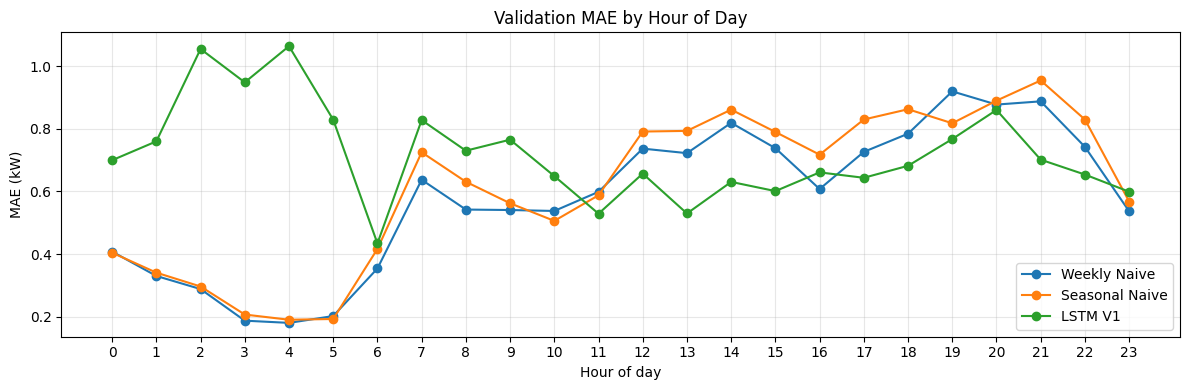

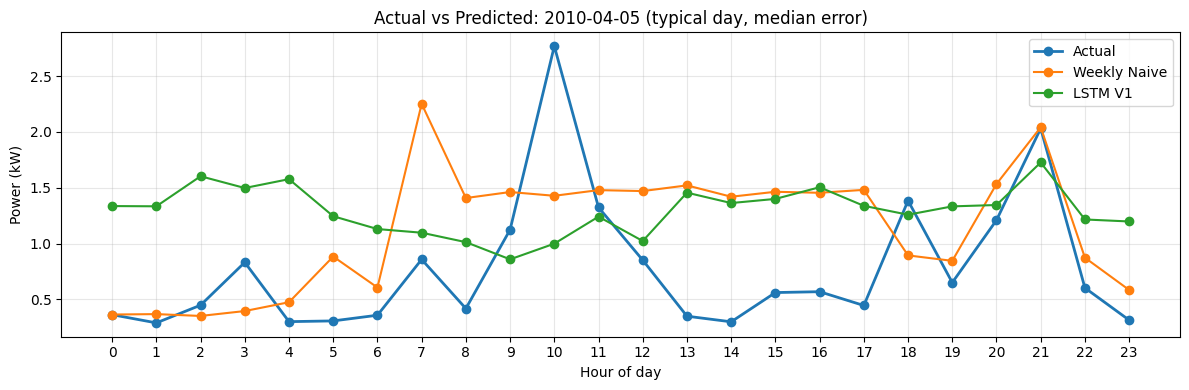

In [ ]:
import matplotlib.pyplot as plt

# 1) MAE by hour of the day
plt.figure(figsize=(12, 4))
for name, P in ea_preds.items():
    plt.plot(range(horizon), np.abs(P - A).mean(axis=0), marker="o", label=name)

plt.title("Validation MAE by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("MAE (kW)")
plt.xticks(range(horizon))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIGS}/powercast_error_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()

# 2) Actual vs predicted on a typical day (median Weekly Naive error)
day_mae = np.abs(ea_preds["Weekly Naive"] - A).mean(axis=1)
typical_day = int(np.argsort(day_mae)[len(day_mae) // 2])
day_date = df.index[val_start + typical_day * horizon].date()

plt.figure(figsize=(12, 4))
plt.plot(A[typical_day], label="Actual", marker="o", linewidth=2)
plt.plot(ea_preds["Weekly Naive"][typical_day], label="Weekly Naive", marker="o")
plt.plot(ea_preds["LSTM V1"][typical_day], label="LSTM V1", marker="o")

plt.title(f"Actual vs Predicted: {day_date} (typical day, median error)")
plt.xlabel("Hour of day")
plt.ylabel("Power (kW)")
plt.xticks(range(horizon))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIGS}/powercast_actual_vs_predicted_typical_day.png", dpi=300, bbox_inches="tight")
plt.show()

**Findings**

- **Night vs day:** Weekly and Seasonal Naive are accurate at night (MAE about 0.2-0.4 kW, hours 0-5), but their error grows during the day and evening (up to about 0.9 kW at hours 19-21). LSTM V1 is the opposite: its night error is high (about 1.05 kW at hours 2 and 4).
- **LSTM behaviour:** LSTM V1 predicts an almost flat line around the average consumption and misses the daily cycle. Its best epoch was the first one, so it is barely trained on the 1,104 non-overlapping windows.
- **Peaks:** All models under-predict high-consumption hours: Weekly Naive by 0.55 kW, Seasonal Naive by 0.65 kW and LSTM V1 by 1.05 kW on average. Weekly Naive finds the exact peak hour on 13.8% of days (29.8% within one hour), Seasonal Naive on 7.2% (26.5%) and LSTM V1 on 5.5% (14.9%). The dashboard's peak-hour alert should be presented as approximate.

### 16. Save LSTM V1 and Scaler

We saved **LSTM V1** and its fitted scaler to the `models` folder in Google Drive (12 Oct). The final notebook (`00_final_demo.ipynb`) loads this exact file as "LSTM V1".

> ⚠️ To keep the final results unchanged, the cell below does **not** save again by default (`SAVE_V1 = False`).

In [ ]:
# LSTM V1 + scaler were saved on 12 Oct: models/powercast_lstm.keras and models/powercast_scaler.pkl
# 00_final_demo.ipynb loads these exact files, so we do NOT overwrite them here.
SAVE_V1 = False   # set to True only to re-create the V1 files on purpose

if SAVE_V1:
    model.save(f"{MODELS}/powercast_lstm.keras")
    joblib.dump(scaler, f"{MODELS}/powercast_scaler.pkl")
    print("LSTM V1 and scaler saved to:", MODELS)
else:
    print("Skipped saving. Using the LSTM V1 files already in:", MODELS)


### 17. Model Limitations (first round, 12 Oct)

- In this first round, Weekly Naive achieved the lowest validation MAE (0.5796 kW). It cannot learn new patterns and fails when the previous week was unusual (holidays, absence from home).
- LSTM V1 did not outperform the naive baselines on MAE. It was trained on non-overlapping windows only (1,104 samples), and its validation loss was best at the first epoch. **Fixed later:** LSTM V3/V4 use a window at every hour and beat all baselines.
- The models rely on historical electricity consumption and do not include external factors such as weather or household activity.
- The dataset represents a single household, so the results may not generalize to other households.
- Final test-set evaluation is done in the combined project notebook (`00_final_demo.ipynb`, section 6).

### 18. First Forecast Function (Weekly Naive, 12 Oct)

In the first round, **Weekly Naive** had the best validation results, so our first forecast function used it: the forecast for hour t is the consumption at hour t-168.

> This function is kept here for reference only. The **final** forecast function uses **LSTM V4** and is in `00_final_demo.ipynb`, section 7a (`predict.py`).

In [ ]:
# 18. Next 24-Hour Forecast Function (Weekly Naive)
import numpy as np

def predict_next_24h(last_168_hours):
    history = np.asarray(last_168_hours, dtype=float).reshape(-1)

    if len(history) != 168:
        raise ValueError("Expected 168 hourly consumption values.")

    if not np.isfinite(history).all():
        raise ValueError("Input contains missing or invalid values.")

    # Weekly Naive: same 24 hours one week earlier (hours t-168 ... t-145)
    return history[:24].copy()

In [ ]:
# Check the forecast function: it must reproduce the Weekly Naive validation forecast
sample_history = df[target].iloc[val_start-168:val_start].to_numpy()

forecast_24h = predict_next_24h(sample_history)

assert np.allclose(forecast_24h, weekly_all[:24])

print("Forecast length:", len(forecast_24h))
print("Forecast unit: kW")
print("Next 24-hour forecast:")
print(np.round(forecast_24h, 4))

Forecast length: 24
Forecast unit: kW
Next 24-hour forecast:
[1.6607 1.4057 1.0993 0.3091 0.3003 0.3508 0.293  0.4319 1.0192 2.0324
 2.7851 0.8776 1.3477 0.9921 1.6163 3.662  1.5948 3.2292 2.6296 1.7162
 1.4938 1.4939 1.6654 1.4545]


### 19. Forecast Function for the Dashboard

The dashboard uses `predict.py` (**LSTM V4**), which is created in `00_final_demo.ipynb`, section 7a.
We removed the old export cell from this notebook so it cannot overwrite the final `predict.py`.

---
### Summary
LSTM V2–V7 (calendar features, training on every hour, calendar of the next 24 hours, day of year, log1p target, season) were added after TA feedback. See `00_final_demo.ipynb`, sections 5d–5k. **LSTM V4 is the final model** (validation MAE 0.464 kW, test MAE 0.409 kW).